# Bài kiểm tra cuối môn Computer Vision

Tổng điểm 100. Hoàn thành các TODO và câu trả lời trong notebook.

- Sử dụng video và model đã cung cấp trong gói đề.
- Được xem tài liệu cá nhân, thực hiện bài độc lập.
- Mỗi track_id chỉ được tạo tối đa một crossing event.
- Không bắt buộc video phải có xe ở cả hai hướng.
- Nộp notebook đã chạy, video kết quả, ảnh vạch và ba CSV yêu cầu.
- Môi trường đã cài requirements.txt trước khi làm bài.

In [1]:
from pathlib import Path
from collections import Counter
import time
import sys
import platform as py_platform
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics

from ultralytics import YOLO
from IPython.display import Video, display

In [2]:
# TODO: xác định thư mục bài, khai báo VIDEO_PATH, MODEL_PATH và OUTPUT_DIR.

def find_sample_root():
    candidates = [
        Path.cwd(),
        Path.cwd() / "01_Bai_mau_Huong_dan",
    ]

    for candidate in candidates:
        if (candidate / "data" / "exam_video.mp4").exists():
            return candidate.resolve()

    raise FileNotFoundError(
        "Không tìm thấy data/exam_video.mp4. "
        "Hãy kiểm tra thư mục bài kiểm tra và mở notebook "
        "trong đúng thư mục chứa data/exam_video.mp4."
    )


ROOT = find_sample_root()

VIDEO_PATH = ROOT / "data" / "exam_video.mp4"
MODEL_PATH = ROOT / "models" / "yolo26n.pt"
OUTPUT_DIR = ROOT / "outputs"

# Tạo thư mục outputs nếu chưa tồn tại
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Kiểm tra các tệp đầu vào
if not VIDEO_PATH.exists():
    raise FileNotFoundError(f"Thiếu video: {VIDEO_PATH}")

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Thiếu model: {MODEL_PATH}")

# Hiển thị thông tin môi trường
environment_info = pd.DataFrame([{
    "Python": sys.version.split()[0],
    "OS": py_platform.system(),
    "OpenCV": cv2.__version__,
    "Ultralytics": ultralytics.__version__,
}])

display(environment_info)

print("Video :", VIDEO_PATH)
print("Model :", MODEL_PATH)
print("Output:", OUTPUT_DIR)


,Python,OS,OpenCV,Ultralytics
0,3.10.11,Windows,5.0.0,8.4.173


Video : C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\data\exam_video.mp4
Model : C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\models\yolo26n.pt
Output: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs


## Phần 1 Metadata và frame đại diện

10 điểm. Đọc metadata, tính thời lượng video và hiển thị frame ở một phần ba video đúng màu.

,Tên video,FPS,Số lượng frame,Chiều rộng (px),Chiều cao (px),Thời lượng (giây),Frame đại diện
0,exam_video.mp4,25.0,300,640,360,12.0,100


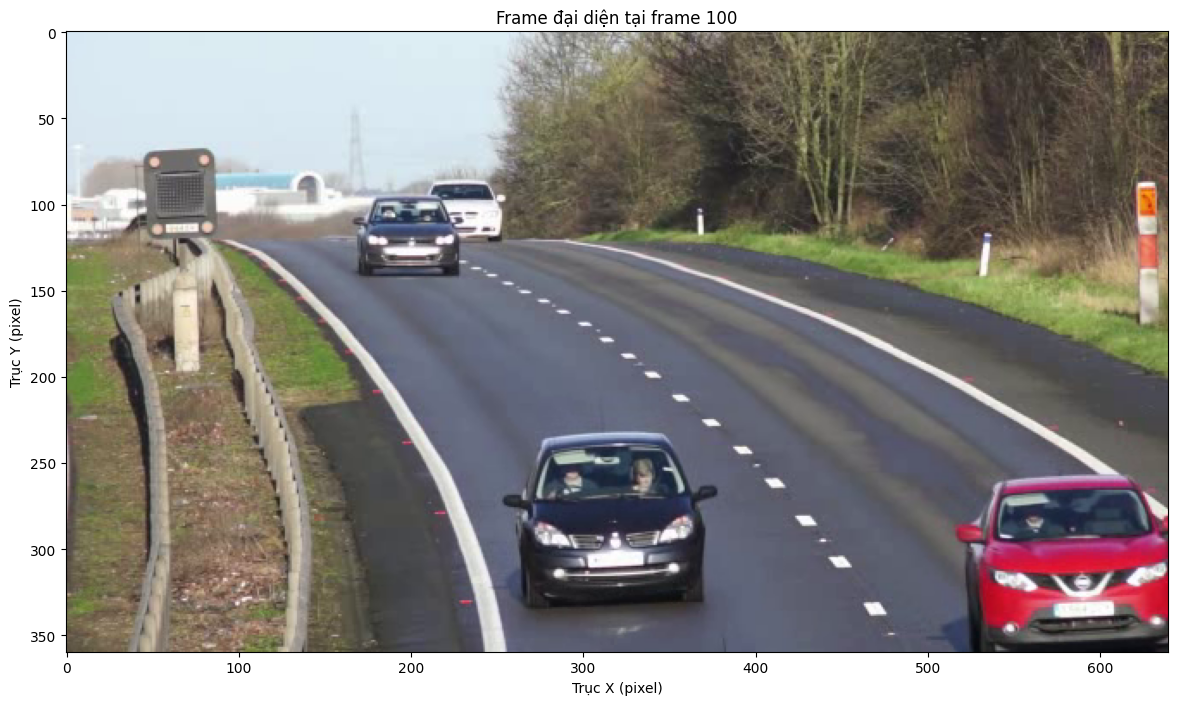

Đã giải phóng tài nguyên video.


In [3]:
# TODO 1: mở video, kiểm tra và đọc FPS, frame_count, width, height.
video_path = Path(VIDEO_PATH)

if not video_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy video: {video_path}"
    )

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    cap.release()
    raise RuntimeError(
        f"Không thể mở video: {video_path}"
    )

try:
    # Đọc metadata
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Kiểm tra metadata hợp lệ
    if fps <= 0 or frame_count <= 0 or width <= 0 or height <= 0:
        raise ValueError(
            "Metadata không hợp lệ. Hãy kiểm tra lại file video."
        )

    # TODO 2: lấy một frame đại diện ở vị trí một phần ba video.
    representative_frame_index = frame_count // 3

    cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        representative_frame_index
    )

    success, frame = cap.read()

    if not success or frame is None:
        raise RuntimeError(
            f"Không đọc được frame số {representative_frame_index}"
        )

    # TODO 3: tính duration_seconds và hiển thị bảng metadata.
    duration_seconds = frame_count / fps

    metadata = pd.DataFrame([{
        "Tên video": video_path.name,
        "FPS": round(fps, 2),
        "Số lượng frame": frame_count,
        "Chiều rộng (px)": width,
        "Chiều cao (px)": height,
        "Thời lượng (giây)": round(duration_seconds, 2),
        "Frame đại diện": representative_frame_index
    }])

    display(metadata)

    # TODO 4: hiển thị frame đại diện đúng màu bằng Matplotlib.
    # OpenCV đọc ảnh theo BGR, Matplotlib cần RGB
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 7))
    plt.imshow(frame_rgb)
    plt.title(
        f"Frame đại diện tại frame {representative_frame_index}"
    )
    plt.xlabel("Trục X (pixel)")
    plt.ylabel("Trục Y (pixel)")
    plt.axis("on")
    plt.tight_layout()
    plt.show()

finally:
    # Giải phóng video sau khi đọc xong,
    # kể cả khi xảy ra lỗi
    cap.release()
    print("Đã giải phóng tài nguyên video.")


## Phần 2 Cấu hình và tracking

30 điểm. Chọn vạch/ROI theo video mới; tự viết tracking, tính tâm và lưu records. Chỉ giữ các lớp car, motorcycle, bus, truck.

LINE_X: 250
ROI_Y: (54, 324)
LINE_MARGIN: 6


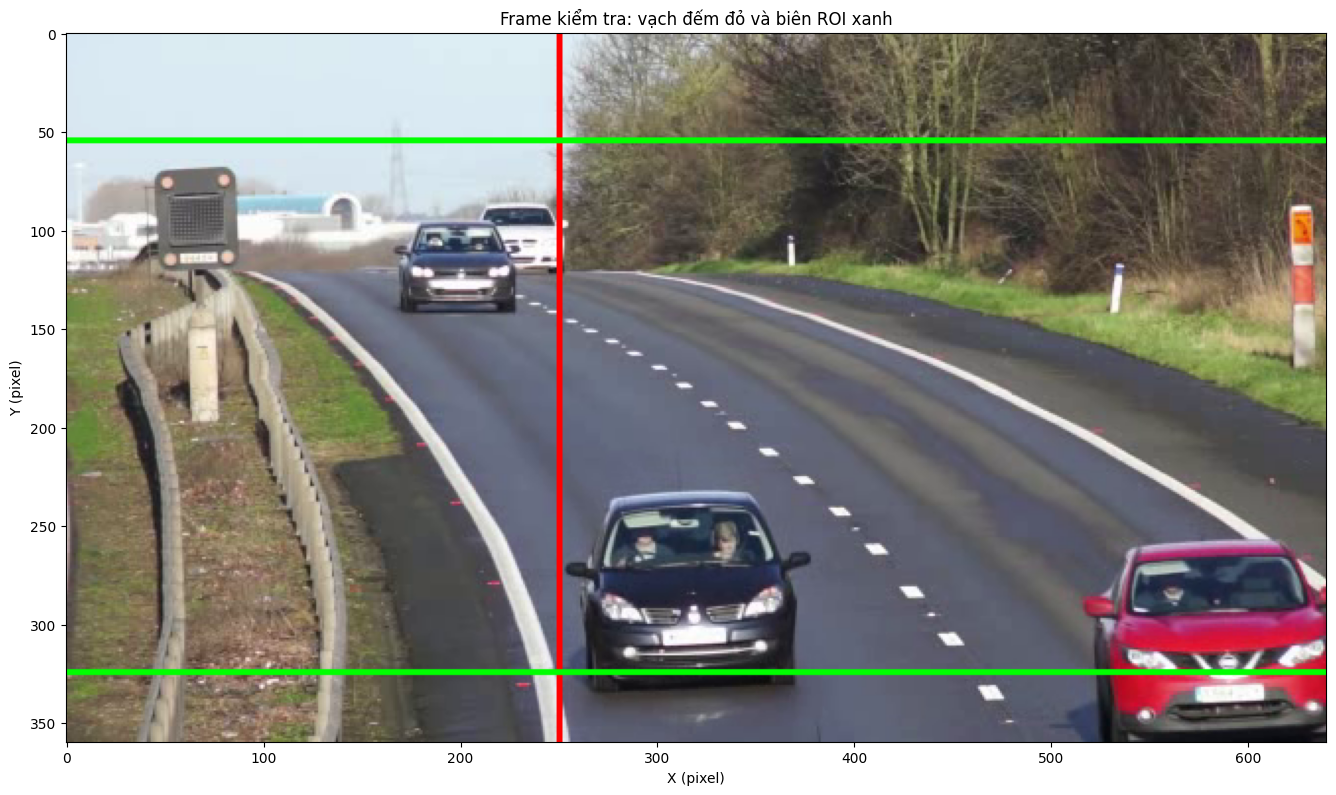

Đã lưu ảnh kiểm tra: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\exam_frame_with_line.jpg


In [4]:
# TODO 5: chọn vạch dọc LINE_X và khoảng ROI_Y theo frame/video mới.
# Có thể mở video bằng phần mềm xem video để xác định đường đi của xe.

LINE_X = 250
ROI_Y = (int(height * 0.15), int(height * 0.90))
LINE_MARGIN = 6

# Kiểm tra cấu hình
ROI_Y_MIN, ROI_Y_MAX = ROI_Y

if not (0 <= LINE_X < width):
    raise ValueError("LINE_X nằm ngoài chiều rộng video.")

if not (0 <= ROI_Y_MIN < ROI_Y_MAX <= height):
    raise ValueError("ROI_Y không hợp lệ.")

if LINE_MARGIN < 0:
    raise ValueError("LINE_MARGIN phải lớn hơn hoặc bằng 0.")

print("LINE_X:", LINE_X)
print("ROI_Y:", ROI_Y)
print("LINE_MARGIN:", LINE_MARGIN)

# TODO 6: vẽ vạch đỏ, hai biên ROI xanh và hiển thị frame đúng màu.
# Lưu frame kiểm tra vào outputs/exam_frame_with_line.jpg.


cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    cap.release()
    raise RuntimeError(f"Không thể mở video: {VIDEO_PATH}")

try:
    cap.set(cv2.CAP_PROP_POS_FRAMES, representative_frame_index)
    success, frame_check = cap.read()

    if not success or frame_check is None:
        raise RuntimeError("Không đọc được frame kiểm tra.")

finally:
    cap.release()

# Sao chép frame để không làm thay đổi ảnh gốc
exam_frame = frame_check.copy()

# Vạch đếm dọc màu đỏ
cv2.line(
    exam_frame,
    (LINE_X, 0),
    (LINE_X, height - 1),
    (0, 0, 255),
    2
)

# Hai biên ROI ngang màu xanh
cv2.line(
    exam_frame,
    (0, ROI_Y_MIN),
    (width - 1, ROI_Y_MIN),
    (0, 255, 0),
    2
)

cv2.line(
    exam_frame,
    (0, ROI_Y_MAX),
    (width - 1, ROI_Y_MAX),
    (0, 255, 0),
    2
)

# Chuyển BGR sang RGB để Matplotlib hiển thị đúng màu
exam_frame_rgb = cv2.cvtColor(
    exam_frame,
    cv2.COLOR_BGR2RGB
)

# Tạo thư mục outputs nếu chưa tồn tại
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Lưu ảnh kiểm tra
exam_frame_path = OUTPUT_DIR / "exam_frame_with_line.jpg"

if not cv2.imwrite(str(exam_frame_path), exam_frame):
    raise RuntimeError(f"Không lưu được ảnh: {exam_frame_path}")

# Hiển thị frame kiểm tra
plt.figure(figsize=(14, 8))
plt.imshow(exam_frame_rgb)
plt.title("Frame kiểm tra: vạch đếm đỏ và biên ROI xanh")
plt.xlabel("X (pixel)")
plt.ylabel("Y (pixel)")
plt.tight_layout()
plt.show()

print("Đã lưu ảnh kiểm tra:", exam_frame_path.resolve())


## Phần 3 Đếm qua vạch

25 điểm. Hoàn thành TODO 7 và TODO 11. Dùng vùng đệm, phía ổn định và counted_ids; lưu hướng cùng timestamp sự kiện.

In [5]:
# TODO 7: trả -1 bên trái, 0 trong vùng đệm, 1 bên phải.
def side_of_line(x, line_x, margin):
    """
    Trả về:
    -1: Bên trái vạch
     0: Trong vùng đệm
     1: Bên phải vạch
    """
    if x < line_x - margin:
        return -1
    elif x > line_x + margin:
        return 1
    else:
        return 0

# Kiểm tra logic trước khi chạy toàn bộ video.
assert side_of_line(LINE_X - LINE_MARGIN - 1, LINE_X, LINE_MARGIN) == -1
assert side_of_line(LINE_X, LINE_X, LINE_MARGIN) == 0
assert side_of_line(LINE_X + LINE_MARGIN + 1, LINE_X, LINE_MARGIN) == 1
print("side_of_line đạt")



side_of_line đạt


In [ ]:
# Tự viết hàm run_tracking_pipeline dựa trên kỹ năng đã học trong bài mẫu.
# Hàm nhận đường dẫn video/model, vạch, ROI, margin, confidence, IoU,
# thư mục output, prefix và save_video.

def run_tracking_pipeline(
    video_path,
    model_path,
    line_x,
    roi_y,
    margin,
    confidence,
    iou,
    output_dir,
    prefix="exam_main",
    save_video=True
):
    start_time = time.time()

    video_path = Path(video_path)
    model_path = Path(model_path)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    if not video_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy video: {video_path}"
        )

    if not model_path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy model: {model_path}"
        )

    # Chỉ giữ bốn lớp phương tiện COCO
    vehicle_classes = {
        2: "car",
        3: "motorcycle",
        5: "bus",
        7: "truck"
    }

    # Header cố định kể cả khi không có dữ liệu
    track_columns = [
        "frame", "time_seconds", "track_id",
        "class_name", "confidence",
        "x1", "y1", "x2", "y2",
        "center_x", "center_y", "inside_roi"
    ]

    event_columns = [
        "track_id", "class_name", "direction",
        "frame", "time_seconds"
    ]

    tracks_records = []
    events_records = []

    # Trạng thái phục vụ đếm qua vạch
    stable_sides = {}
    counted_ids = set()

    # TODO 8: nạp model, chạy YOLO kết hợp ByteTrack và duy trì ID qua các frame.
    # Chỉ giữ car, motorcycle, bus, truck.
    model = YOLO(str(model_path))

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        cap.release()
        raise RuntimeError(
            f"Không thể mở video: {video_path}"
        )

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    if fps <= 0:
        cap.release()
        raise ValueError("FPS của video không hợp lệ.")

    roi_y_min, roi_y_max = roi_y

    if not (0 <= line_x < width):
        cap.release()
        raise ValueError("LINE_X nằm ngoài khung hình.")

    if not (0 <= roi_y_min < roi_y_max <= height):
        cap.release()
        raise ValueError("ROI_Y không hợp lệ.")

    video_out = (
        output_dir / f"{prefix}_tracked.mp4"
        if save_video else None
    )

    writer = None

    if save_video:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        writer = cv2.VideoWriter(
            str(video_out),
            fourcc,
            fps,
            (width, height)
        )

        if not writer.isOpened():
            cap.release()
            writer.release()
            raise RuntimeError(
                f"Không tạo được video đầu ra: {video_out}"
            )

    frame_idx = 0
    detections_with_id = 0

    try:
        while True:
            success, frame = cap.read()

            if not success:
                break

            # TODO 8: YOLO + ByteTrack
            results = model.track(
                source=frame,
                persist=True,
                tracker="bytetrack.yaml",
                classes=list(vehicle_classes.keys()),
                conf=confidence,
                iou=iou,
                verbose=False
            )

            result = results[0]

            # Vẽ vạch dọc và hai biên ROI
            cv2.line(
                frame,
                (line_x, 0),
                (line_x, height - 1),
                (0, 0, 255),
                2
            )

            cv2.line(
                frame,
                (0, roi_y_min),
                (width - 1, roi_y_min),
                (0, 255, 0),
                2
            )

            cv2.line(
                frame,
                (0, roi_y_max),
                (width - 1, roi_y_max),
                (0, 255, 0),
                2
            )

            boxes = result.boxes

            if boxes is not None and len(boxes) > 0:
                xyxy = boxes.xyxy.cpu().numpy()
                cls_ids = boxes.cls.cpu().numpy().astype(int)
                confs = boxes.conf.cpu().numpy()

                if boxes.id is not None:
                    ids = (
                        boxes.id.cpu().numpy().astype(int)
                    )
                else:
                    ids = [None] * len(xyxy)

                for box, cls_id, conf, track_id in zip(
                    xyxy, cls_ids, confs, ids
                ):
                    if cls_id not in vehicle_classes:
                        continue

                    if track_id is None:
                        continue

                    track_id = int(track_id)
                    detections_with_id += 1

                    x1, y1, x2, y2 = map(
                        int, box.tolist()
                    )

                    # TODO 9: tính tâm box và xác định tâm có nằm trong ROI hay không.
                    center_x = int((x1 + x2) / 2)
                    center_y = int((y1 + y2) / 2)

                    inside_roi = (
                        roi_y_min <= center_y <= roi_y_max
                    )

                    class_name = vehicle_classes[cls_id]
                    time_seconds = frame_idx / fps

                    # TODO 10: thu thập dữ liệu track và lưu CSV theo các trường bên dưới.
                    tracks_records.append({
                        "frame": frame_idx,
                        "time_seconds": time_seconds,
                        "track_id": track_id,
                        "class_name": class_name,
                        "confidence": float(conf),
                        "x1": x1,
                        "y1": y1,
                        "x2": x2,
                        "y2": y2,
                        "center_x": center_x,
                        "center_y": center_y,
                        "inside_roi": bool(inside_roi)
                    })

                    # TODO 11: ghi sự kiện qua vạch, duy trì phía ổn định và chống đếm trùng ID.
                    if inside_roi:
                        current_side = side_of_line(
                            center_x, line_x, margin
                        )

                        if current_side != 0:
                            previous_side = stable_sides.get(
                                track_id
                            )

                            if previous_side is None:
                                # Lần đầu quan sát được phía ổn định
                                stable_sides[track_id] = current_side

                            elif current_side != previous_side:
                                # ID chỉ được đếm một lần
                                if track_id not in counted_ids:
                                    if (
                                        previous_side == -1
                                        and current_side == 1
                                    ):
                                        direction = "left_to_right"
                                    elif (
                                        previous_side == 1
                                        and current_side == -1
                                    ):
                                        direction = "right_to_left"
                                    else:
                                        direction = None

                                    if direction is not None:
                                        events_records.append({
                                            "track_id": track_id,
                                            "class_name": class_name,
                                            "direction": direction,
                                            "frame": frame_idx,
                                            "time_seconds": time_seconds
                                        })

                                        counted_ids.add(track_id)

                                # Cập nhật phía ổn định
                                stable_sides[track_id] = current_side

                    # Vẽ bounding box, tâm và ID
                    cv2.rectangle(
                        frame,
                        (x1, y1),
                        (x2, y2),
                        (255, 180, 0),
                        2
                    )

                    cv2.circle(
                        frame,
                        (center_x, center_y),
                        4,
                        (255, 0, 255),
                        -1
                    )

                    label = (
                        f"{class_name} ID:{track_id} "
                        f"{conf:.2f}"
                    )

                    cv2.putText(
                        frame,
                        label,
                        (x1, max(20, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.55,
                        (255, 180, 0),
                        2
                    )

            # Hiển thị số sự kiện đã đếm
            cv2.putText(
                frame,
                f"Crossings: {len(events_records)}",
                (20, 35),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.9,
                (0, 255, 255),
                2
            )

            if writer is not None:
                writer.write(frame)

            frame_idx += 1

    finally:
        cap.release()

        if writer is not None:
            writer.release()

    # Tạo DataFrame, bảo đảm có header nếu rỗng
    tracks_df = pd.DataFrame(
        tracks_records, columns=track_columns
    )

    events_df = pd.DataFrame(
        events_records, columns=event_columns
    )

    # Lưu CSV
    tracks_csv = output_dir / f"{prefix}_tracks.csv"
    events_csv = output_dir / f"{prefix}_events.csv"

    tracks_df.to_csv(
        tracks_csv, index=False, encoding="utf-8-sig"
    )

    events_df.to_csv(
        events_csv, index=False, encoding="utf-8-sig"
    )

    processing_seconds = time.time() - start_time

    run_info = {
        "confidence": confidence,
        "iou": iou,
        "detections_with_id": detections_with_id,
        "unique_track_ids": int(
            tracks_df["track_id"].nunique()
        ),
        "crossing_events": len(events_df),
        "processing_seconds": round(processing_seconds, 2)
    }

    print("Đã lưu tracks:", tracks_csv.resolve())
    print("Đã lưu events:", crossing_events_csv.resolve())

    if video_out is not None:
        print("Đã lưu video:", video_out.resolve())

    return tracks_df, events_df, video_out, run_info

# Lưu video có box, ID, vạch, ROI và bộ đếm khi save_video=True.
# Đóng tài nguyên sau khi xử lý xong.
# CSV tracks: frame, time_seconds, track_id, class_name, confidence,
# x1, y1, x2, y2, center_x, center_y, inside_roi.
# CSV events: track_id, class_name, direction, frame, time_seconds.
# direction dùng left_to_right hoặc right_to_left; CSV rỗng vẫn có header.
# Hàm trả tracks_df, events_df, video_out, run_info.
# run_info gồm confidence, detections_with_id, unique_track_ids, crossing_events.
# Có thể bổ sung processing_seconds để tham khảo, không bắt buộc.


In [7]:
# TODO 12: khai báo confidence 0.20 và IoU 0.50 cho cấu hình chính.
# Gọi run_tracking_pipeline với prefix="exam_main", save_video=True.
# Nhận đủ bốn output: tracks_df, events_df, video_out, main_run_info.
# Hiển thị bảng main_run_info, tracks_df.head(), events_df và video output.
# Nếu video không phát inline, mở file outputs/exam_main_tracked.mp4 trực tiếp.
CONFIDENCE = 0.20
IOU = 0.50

# Chạy tracking
tracks_df, events_df, video_out, main_run_info = (
    run_tracking_pipeline(
        video_path=VIDEO_PATH,
        model_path=MODEL_PATH,
        line_x=LINE_X,
        roi_y=ROI_Y,
        margin=LINE_MARGIN,
        confidence=CONFIDENCE,
        iou=IOU,
        output_dir="outputs",
        prefix="exam_main",
        save_video=True
    )
)

# Hiển thị thông tin lần chạy
print("=== MAIN RUN INFO ===")
display(pd.DataFrame([main_run_info]))

# Hiển thị các track đầu tiên
print("=== TRACKS: 5 DÒNG ĐẦU ===")
display(tracks_df.head())

# Hiển thị các sự kiện qua vạch
print("=== CROSSING EVENTS ===")
display(events_df)

# Phát video đầu ra trong notebook
if video_out is not None and Path(video_out).exists():
    display(Video(
        filename=str(video_out),
        embed=True,
        width=800
    ))
else:
    print("Không tìm thấy video đầu ra.")


Đã lưu tracks: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\exam_main_tracks.csv
Đã lưu events: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\exam_main_events.csv
Đã lưu video: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\exam_main_tracked.mp4
=== MAIN RUN INFO ===


,confidence,iou,detections_with_id,unique_track_ids,crossing_events,processing_seconds
0,0.2,0.5,1873,31,6,8.26


=== TRACKS: 5 DÒNG ĐẦU ===


,frame,time_seconds,track_id,class_name,confidence,x1,y1,x2,y2,center_x,center_y,inside_roi
0,0,0.0,1,car,0.868228,401,152,497,224,449,188,True
1,0,0.0,2,car,0.816172,284,283,406,358,345,320,True
2,0,0.0,3,car,0.777931,211,131,292,195,251,163,True
3,0,0.0,4,car,0.766562,260,183,355,262,307,222,True
4,0,0.0,5,car,0.695533,195,113,257,170,226,141,True


=== CROSSING EVENTS ===


,track_id,class_name,direction,frame,time_seconds
0,5,car,left_to_right,23,0.92
1,6,car,left_to_right,60,2.40
2,14,car,left_to_right,127,5.08
3,8,car,left_to_right,144,5.76
4,52,car,left_to_right,252,10.08
5,69,truck,left_to_right,295,11.80


## Phần 4 Thí nghiệm confidence

20 điểm. Chạy hai cấu hình, lập bảng và nhận xét kết quả. Không chấm theo tốc độ máy.

In [8]:
# TODO 13: chạy lại pipeline với confidence 0.20 và 0.50.
# Giữ các tham số khác cố định, dùng prefix khác nhau và không ghi lại video.
# Tạo bảng gồm confidence, detections_with_id, unique_track_ids, crossing_events.
# Lưu outputs/parameter_comparison.csv và hiển thị bảng.

# Giữ nguyên các tham số khác
IOU = 0.50

confidence_values = [0.20, 0.50]
comparison_results = []

for conf_value in confidence_values:
    print(f"\nĐang chạy confidence = {conf_value:.2f}")

    # Chạy lại pipeline, không lưu video
    tracks_df_exp, events_df_exp, video_exp, run_info_exp = (
        run_tracking_pipeline(
            video_path=VIDEO_PATH,
            model_path=MODEL_PATH,
            line_x=LINE_X,
            roi_y=ROI_Y,
            margin=LINE_MARGIN,
            confidence=conf_value,
            iou=IOU,
            output_dir="outputs",
            prefix=f"confidence_{int(conf_value * 100)}",
            save_video=False
        )
    )

    # Thu thập các chỉ số cần so sánh
    comparison_results.append({
        "confidence": conf_value,
        "detections_with_id": run_info_exp["detections_with_id"],
        "unique_track_ids": run_info_exp["unique_track_ids"],
        "crossing_events": run_info_exp["crossing_events"]
    })

# Tạo bảng so sánh
comparison_df = pd.DataFrame(
    comparison_results,
    columns=[
        "confidence",
        "detections_with_id",
        "unique_track_ids",
        "crossing_events"
    ]
)

# Lưu bảng ra CSV
comparison_path = Path("outputs") / "parameter_comparison.csv"
comparison_path.parent.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8-sig"
)

# Hiển thị kết quả
print("\n=== BẢNG SO SÁNH CONFIDENCE ===")
display(comparison_df)

print("Đã lưu bảng tại:", comparison_path.resolve())

IOU = 0.50

confidence_values = [0.20, 0.50]
comparison_results = []

for conf_value in confidence_values:
    print(f"\nĐang chạy confidence = {conf_value:.2f}")

    # Chạy lại pipeline, không lưu video
    tracks_df_exp, events_df_exp, video_exp, run_info_exp = (
        run_tracking_pipeline(
            video_path=VIDEO_PATH,
            model_path=MODEL_PATH,
            line_x=LINE_X,
            roi_y=ROI_Y,
            margin=LINE_MARGIN,
            confidence=conf_value,
            iou=IOU,
            output_dir="outputs",
            prefix=f"confidence_{int(conf_value * 100)}",
            save_video=False
        )
    )

    # Thu thập các chỉ số cần so sánh
    comparison_results.append({
        "confidence": conf_value,
        "detections_with_id": run_info_exp["detections_with_id"],
        "unique_track_ids": run_info_exp["unique_track_ids"],
        "crossing_events": run_info_exp["crossing_events"]
    })

# Tạo bảng so sánh
comparison_df = pd.DataFrame(
    comparison_results,
    columns=[
        "confidence",
        "detections_with_id",
        "unique_track_ids",
        "crossing_events"
    ]
)

# Lưu bảng ra CSV
comparison_path = Path("outputs") / "parameter_comparison.csv"
comparison_path.parent.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    comparison_path,
    index=False,
    encoding="utf-8-sig"
)

# Hiển thị kết quả
print("\n=== BẢNG SO SÁNH CONFIDENCE ===")
display(comparison_df)

print("Đã lưu bảng tại:", comparison_path.resolve())



Đang chạy confidence = 0.20
Đã lưu tracks: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_20_tracks.csv
Đã lưu events: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_20_events.csv

Đang chạy confidence = 0.50
Đã lưu tracks: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_50_tracks.csv
Đã lưu events: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_50_events.csv

=== BẢNG SO SÁNH CONFIDENCE ===


,confidence,detections_with_id,unique_track_ids,crossing_events
0,0.2,1873,31,6
1,0.5,1220,15,5


Đã lưu bảng tại: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\parameter_comparison.csv

Đang chạy confidence = 0.20
Đã lưu tracks: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_20_tracks.csv
Đã lưu events: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_20_events.csv

Đang chạy confidence = 0.50
Đã lưu tracks: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_50_tracks.csv
Đã lưu events: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\confidence_50_events.csv

=== BẢNG SO SÁNH CONFIDENCE ===


,confidence,detections_with_id,unique_track_ids,crossing_events
0,0.2,1873,31,6
1,0.5,1220,15,5


Đã lưu bảng tại: C:\Users\ADMIN\Desktop\Fundamentals of Computer Vision\Kiểm tra cuối kỳ\outputs\parameter_comparison.csv


### Nhận xét thí nghiệm

Viết 2–3 câu: chỉ ra thay đổi trong bảng, giải thích tác động của confidence và giới hạn khi chưa có ground truth. Số event bằng nhau giữa hai cấu hình vẫn là kết quả hợp lệ.

**Nhận xét:**

Khi tăng `confidence` từ 0.20 lên 0.50, số detection có ID giảm từ 1.873 xuống 1.220, số track duy nhất giảm từ 31 xuống 15 và số sự kiện qua vạch giảm từ 6 xuống 5. Điều này cho thấy ngưỡng confidence cao hơn loại bỏ nhiều phát hiện có độ tin cậy thấp, nhưng cũng có thể khiến một số phương tiện bị bỏ sót. Do chưa có **ground truth** để đối chiếu.

## Phần 5 Phân tích

15 điểm. Mỗi câu trả lời 1–3 câu.

1. YOLO và ByteTrack đảm nhiệm vai trò gì?
**Trả lời:**
- YOLO có nhiệm vụ phát hiện phương tiện trong từng khung hình, xác định loại phương tiện và bounding box. ByteTrack liên kết các đối tượng giữa các khung hình để duy trì track_id, giúp theo dõi phương tiện và hỗ trợ đếm số lượt qua vạch.

2. Nêu một nguyên nhân gây đổi ID và ảnh hưởng tới bộ đếm.
**Trả lời:**
- Khi phương tiện bị che khuất trong một khoảng thời gian, ByteTrack có thể không duy trì được ID cũ và gán ID mới khi phát hiện lại. Điều này có thể khiến bộ đếm ghi nhận một phương tiện thành nhiều lượt qua vạch.

3. Muốn tính MOTA hoặc IDF1 cần dữ liệu gì?
**Trả lời:**
- Cần dữ liệu ground truth được gán nhãn cho video, bao gồm bounding box, danh tính (ID) của từng đối tượng qua các khung hình và thông tin đối chiếu với kết quả dự đoán. MOTA đánh giá lỗi phát hiện và theo dõi, còn IDF1 đánh giá mức độ nhất quán của danh tính đối tượng.

4. Disparity tăng gấp đôi thì depth thay đổi thế nào nếu focal length và baseline cố định?
**Trả lời:**
- Theo công thức \(Z=\frac{fB}{d}\), khi disparity tăng gấp đôi và focal length \(f\), baseline \(B\) không đổi, depth giảm còn một nửa. Điều này có nghĩa là vật thể được ước tính ở gần camera hơn.

5. Voxel size quá lớn ảnh hưởng vật cản nhỏ thế nào?
**Trả lời:**
- Voxel size quá lớn làm giảm độ chi tiết của đám mây điểm, khiến vật cản nhỏ có thể bị gộp vào các voxel lớn hoặc bị bỏ sót. Vì vậy, khả năng phát hiện và xác định chính xác vị trí vật cản sẽ giảm.

## Kiểm tra và nộp bài

- Chạy lại notebook từ đầu.
- outputs/exam_main_tracked.mp4
- outputs/exam_frame_with_line.jpg
- outputs/exam_main_tracks.csv
- outputs/exam_main_crossing_events.csv
- outputs/parameter_comparison.csv
- Notebook đã chạy và đã viết nhận xét, câu trả lời.

Nén thành MSSV_HoTen_FinalCV.zip. Không nộp .venv, model hoặc video nguồn.